# El ajuste a prueba de fuga de la tarjeta de puntaje monótona, leído de vuelta sobre las tarjetas de Taiwán

**Pregunta:** ¿Qué partes del ajuste de C01 pueden ver qué tarjetas, y gana la tarjeta de puntaje ajustada sus trece variables frente a una línea base de una sola variable en 9.000 tarjetas que ningún paso del ajuste ha visto?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar el diseño del ajuste de C01 a prueba de fuga: qué se aparta, para qué puede usarse cada parte y qué se ajusta solo con la parte de entrenamiento;
- verificar en los conteos versionados que los tramos aprendidos respetan sus restricciones (al menos 5% de las tarjetas por tramo, una tasa de incumplimiento que sigue su dirección);
- ubicar tarjetas crudas en los tramos aprendidos a mano y reconstruir su puntaje como suma de puntos, sin ningún objeto de modelo;
- comparar la tarjeta de puntaje con una línea base de una sola variable en 9.000 tarjetas reservadas con el AUC, el KS, DeLong, el chi cuadrado y las pruebas de nivel del motor.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation.calibration import pd_brier, pd_chi2_grades, pd_ece, pd_jeffreys
from riskvalidation.validation.discrimination import auc_with_variance, disc_auc, disc_delong, disc_ks

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso es el del notebook 01: C01, el archivo de tarjetas de crédito de Taiwán de UCI (Yeh, 2009; dueño: UCI Machine Learning Repository; CC BY 4.0, clase de licencia `mirror-allowed`; https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), 30.000 tarjetas. El ajuste mismo corre en la cadena de cálculo (`data-pipeline/pipeline/model/scorecard.py`, con `optbinning`, `statsmodels` y `scikit-learn`) sobre el archivo crudo, que vive fuera del repositorio, bajo la raíz de datos. Este notebook lee lo que el ajuste versionó, así que no necesita ni el archivo crudo ni esas bibliotecas:

- `data/derived/C01/models-taiwan.json`: la división, las variables con sus restricciones, los puntos de corte aprendidos, los coeficientes y la tabla de puntos con los conteos de entrenamiento de cada tramo.
- `data/derived/C01/holdout.json`: la muestra de 50 tarjetas con entradas crudas, puntos, puntaje y PD; la curva CAP, la curva ROC, la tabla de grados y los tramos de confiabilidad de cada modelo en las 9.000 tarjetas reservadas; y las filas de prueba versionadas.

La siguiente celda carga ambos archivos.

In [2]:
# Cargar los dos archivos versionados del caso C01 (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
models = json.loads((derived / "models-taiwan.json").read_text(encoding="utf-8"))
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))
fit = models["fit"]
card = next(m for m in models["model"] if m["id"] == "P1-scorecard")["details"]
table = card["points_table"]
sample = holdout["outputs"]["sample"]
rungs = holdout["outputs"]["rungs"]
policy = rv.default_policy()
LIGHT = {"green": "verde", "amber": "ámbar", "red": "roja", "not_evaluated": "ninguna"}
rows_total = sum(fit["split"][s]["n"] for s in ("train", "calibration", "holdout"))
print("semilla del cálculo:", fit["seed"], "| filas del archivo:", rows_total)
print("calculado por riskvalidation", models["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

semilla del cálculo: 42 | filas del archivo: 30000
calculado por riskvalidation 1.0.1 | instalado 1.0.1


## Método

### Paso 1: qué puede ver qué, la división a prueba de fuga

Las reglas de investigación para todo ajuste de puntuación (dossier 04 de la base de investigación del producto, "reglas universales de fuga") dicen que toda transformación se **ajusta solo con la parte de entrenamiento** (agrupación en tramos, WoE, imputación, escalamiento, selección de variables), que un mapa de calibración se ajusta con una parte de calibración **separada** y nunca con la de prueba, y que nada se remuestrea antes de medir la calibración. El caso C01 las aplica con una división estratificada con semilla fija: 56% de las tarjetas para ajustar, 14% para calibrar a los retadores del notebook 06 y una muestra reservada bloqueada de 30% que ningún paso del ajuste ha visto. La tarjeta de puntaje usa solo la parte de entrenamiento. La celda dibuja el tamaño y la tasa de incumplimiento de cada parte desde el registro del ajuste.

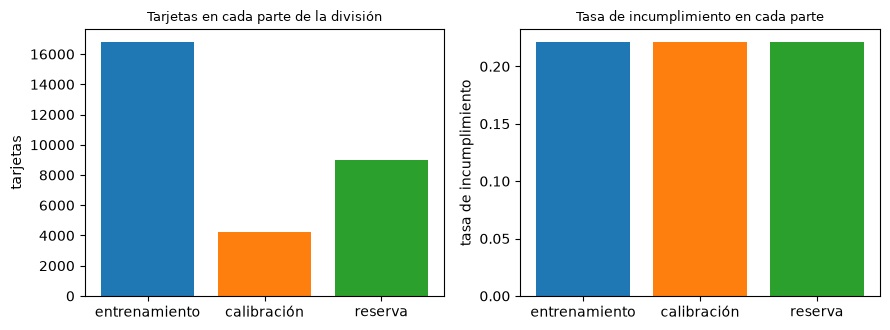

tarjetas en cada parte: [16800, 4200, 9000]
proporción de las tarjetas en cada parte: [0.56, 0.14, 0.3]
dispersión de la tasa de incumplimiento entre las partes: 3e-05


In [3]:
# Dibujar las tres partes de la división con sus tasas de incumplimiento
split = fit["split"]
slices = ["train", "calibration", "holdout"]
cards = [split[s]["n"] for s in slices]
rates = [split[s]["default_rate"] for s in slices]
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.4))
left.bar(["entrenamiento", "calibración", "reserva"], cards, color=["tab:blue", "tab:orange", "tab:green"])
left.set_ylabel("tarjetas")
left.set_title("Tarjetas en cada parte de la división", fontsize=9)
right.bar(["entrenamiento", "calibración", "reserva"], rates, color=["tab:blue", "tab:orange", "tab:green"])
right.set_ylabel("tasa de incumplimiento")
right.set_title("Tasa de incumplimiento en cada parte", fontsize=9)
fig.tight_layout()
plt.show()
print("tarjetas en cada parte:", cards)
print("proporción de las tarjetas en cada parte:", [round(c / sum(cards), 2) for c in cards])
print("dispersión de la tasa de incumplimiento entre las partes:", round(max(rates) - min(rates), 5))

El panel izquierdo muestra las tres partes con 16.800, 4.200 y 9.000 tarjetas, las proporciones 0,56, 0,14 y 0,3 de las 30.000 del archivo. El panel derecho es el sentido de estratificar: las tres tasas de incumplimiento son la misma, 22,1%, y su dispersión es 3e-05, de modo que la muestra reservada es una muestra justa de la población con que se ajustó la tarjeta de puntaje y una brecha entre el desempeño de entrenamiento y el de la muestra reservada no puede atribuirse a una mezcla distinta de tarjetas buenas y malas. Lo que la figura no puede mostrar es que nada se filtró: eso es una propiedad de la ruta de ajuste, resguardada por una prueba de la cadena de cálculo (`tests/test_leakage.py`, que muestra el notebook 07), y aquí solo se ve a través de los conteos del paso siguiente.

### Paso 2: los tramos aprendidos y sus restricciones

Cada variable lleva una **restricción monótona**, la dirección en que su tasa de incumplimiento puede moverse a lo largo de los tramos: ascendente para los meses de atraso (más atraso, más incumplimiento), descendente para el límite de crédito y los montos de pago, libre para el resto. Una agrupación monótona mantiene explicable la tarjeta de puntaje, porque un límite mayor nunca puede comprar un puntaje peor. El ajuste exige además que cada tramo reúna al menos 5% de las tarjetas, para que su tasa de incumplimiento descanse en suficientes incumplimientos. Ambas propiedades pueden verificarse en los conteos que versiona la tabla de puntos, y los mismos conteos muestran dónde se aprendieron los tramos: suman las 16.800 tarjetas de entrenamiento en cada variable. La celda calcula la proporción del tramo más pequeño y la dirección de la tasa de incumplimiento de las 13 variables retenidas, y grafica las proporciones mínimas junto a la tasa de incumplimiento a lo largo de los tramos de dos variables.

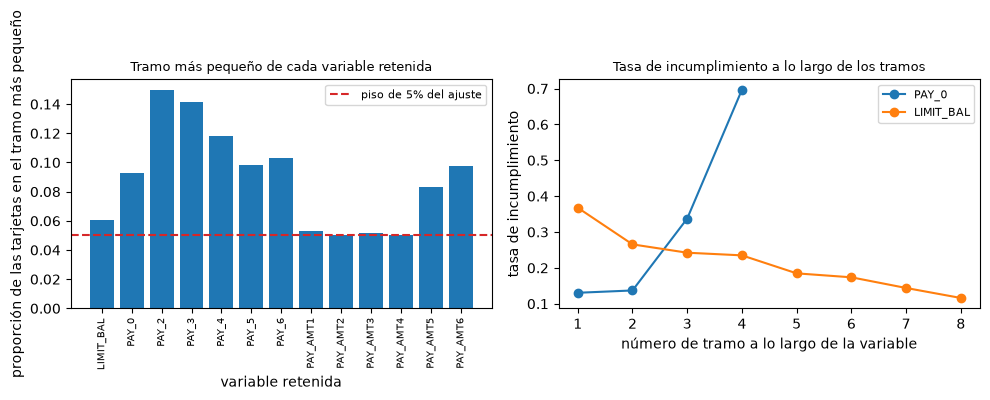

variables cuyo tramo más pequeño reúne al menos 5%: 13 de 13
variables cuya tasa de incumplimiento sigue su restricción: 13 de 13


In [4]:
# Proporción del tramo más pequeño y dirección de la tasa de incumplimiento de cada variable, desde los conteos
constraint = {v["name"]: v["monotone"] for v in fit["features"]}
smallest, follows = {}, {}
for name in card["features"]:
    rows = [r for r in table if r["feature"] == name and r["count"] > 0]
    steps = np.diff([r["event_rate"] for r in rows])
    smallest[name] = min(r["count"] for r in rows) / sum(r["count"] for r in rows)
    follows[name] = bool((steps >= 0).all() if constraint[name] == 1 else (steps <= 0).all())
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(list(smallest), list(smallest.values()), color="tab:blue")
left.axhline(0.05, color="tab:red", linestyle="--", label="piso de 5% del ajuste")
left.tick_params(axis="x", labelrotation=90, labelsize=7)
left.set_xlabel("variable retenida")
left.set_ylabel("proporción de las tarjetas en el tramo más pequeño")
left.set_title("Tramo más pequeño de cada variable retenida", fontsize=9)
left.legend(fontsize=8)
for name in ("PAY_0", "LIMIT_BAL"):
    rows = [r for r in table if r["feature"] == name and r["count"] > 0]
    right.plot(range(1, len(rows) + 1), [r["event_rate"] for r in rows], marker="o", label=name)
right.set_xlabel("número de tramo a lo largo de la variable")
right.set_ylabel("tasa de incumplimiento")
right.set_title("Tasa de incumplimiento a lo largo de los tramos", fontsize=9)
right.legend(fontsize=8)
fig.tight_layout()
plt.show()
big_enough = sum(v >= 0.05 for v in smallest.values())
print("variables cuyo tramo más pequeño reúne al menos 5%:", big_enough, "de", len(smallest))
print("variables cuya tasa de incumplimiento sigue su restricción:", sum(follows.values()), "de", len(follows))

Las 13 variables conservan un tramo mínimo sobre la línea roja de 5% (el más angosto queda apenas sobre 5%), y las 13 tasas de incumplimiento siguen su restricción. El panel derecho muestra las dos direcciones: la tasa de `PAY_0` sube de cerca de 13% a cerca de 70% en sus cuatro tramos, mientras la de `LIMIT_BAL` baja en ocho tramos a medida que crece el límite. La figura no muestra que los puntos de corte sean los mejores posibles, solo que obedecen las reglas; la elección de los puntos de corte es la optimización de la cadena de cálculo (Navas-Palencia, 2020).

### Paso 3: ubicar tarjetas crudas en los tramos y sumar los puntos

Una tarjeta de puntaje es auditable porque su puntaje no necesita ningún objeto de modelo. Para cada una de las 13 variables, la siguiente celda cuenta los puntos de corte menores o iguales al valor crudo de la tarjeta (`numpy.searchsorted` con `side="right"`, que es exactamente la regla de intervalo semiabierto de un tramo), lee los puntos de esa fila de la tabla y suma los 13 números. Las 50 tarjetas de la muestra reservada traen sus entradas crudas, así que la suma puede ponerse junto al puntaje que guardó la cadena de cálculo. La celda imprime cuántas de las 650 celdas de puntos y de los 50 puntajes coinciden, y dibuja el histograma de los puntajes reconstruidos, con los incumplidores apilados sobre los demás.

celdas de puntos iguales a las guardadas: 650 de 650
puntajes iguales a los guardados: 50 de 50
AUC del puntaje entero solo, 50 tarjetas: 0.7781


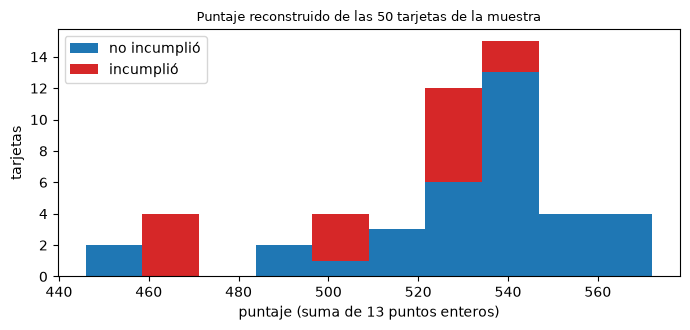

In [5]:
# Ubicar las entradas crudas de las 50 tarjetas en los tramos aprendidos, sumar sus puntos y comparar con el puntaje
inputs = sample["inputs"]
columns = []
for name in card["features"]:
    rows = [r for r in table if r["feature"] == name]
    cuts = card["bins"][name]["splits"]
    index = np.searchsorted(cuts, np.array(inputs[name], dtype=float), side="right")
    columns.append([rows[i]["points"] for i in index])
points = np.array(columns).T
score = points.sum(axis=1)
y50 = np.array(sample["targets"])
same_points = int((points == np.array(sample["scorecard_points"])).sum())
same_score = int((score == np.array(sample["scorecard_score"])).sum())
print("celdas de puntos iguales a las guardadas:", same_points, "de", points.size)
print("puntajes iguales a los guardados:", same_score, "de", len(score))
auc_score = disc_auc(-score.astype(float), y50, policy=policy, model_id="P1-scorecard")
print("AUC del puntaje entero solo, 50 tarjetas:", round(auc_score.metric, 4))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist([score[y50 == 0], score[y50 == 1]], bins=10, stacked=True, color=["tab:blue", "tab:red"],
        label=["no incumplió", "incumplió"])
ax.set_xlabel("puntaje (suma de 13 puntos enteros)")
ax.set_ylabel("tarjetas")
ax.set_title("Puntaje reconstruido de las 50 tarjetas de la muestra", fontsize=9)
ax.legend()
fig.tight_layout()
plt.show()

Las 650 celdas de puntos y los 50 puntajes coinciden con lo que guardó la cadena de cálculo: un puntaje no es más que la suma de 13 consultas a la tabla. El histograma muestra para qué sirve la suma. Ordenadas solo por el puntaje entero, sin PD y sin modelo, el motor da un AUC de 0,7781 en estas tarjetas. Las tarjetas que incumplieron (rojo) tienden a quedar en el extremo bajo del rango de puntajes, mientras los puntajes altos son mayormente azules. Con 15 incumplidores entre 50 tarjetas la imagen es un esbozo, no una medición, y los pasos siguientes le ponen números.

### Paso 4: lo que decidió el paso logístico

El paso logístico fijó un coeficiente por variable. Su efecto sobre una tarjeta es la **dispersión de los puntos** de la variable: los puntos de su mejor tramo menos los de su peor tramo, $\mathrm{Factor}\,|\beta_j|\,(\max_b \mathrm{WoE}_{j,b} - \min_b \mathrm{WoE}_{j,b})$. Una variable con dispersión amplia puede mover mucho el puntaje de una tarjeta; una con dispersión estrecha casi no importa. Es la lectura propia de la tarjeta de puntaje de qué variables mueven el puntaje, el número que citaría un analista de crédito. La celda calcula la dispersión desde la tabla versionada y la dibuja, de mayor a menor.

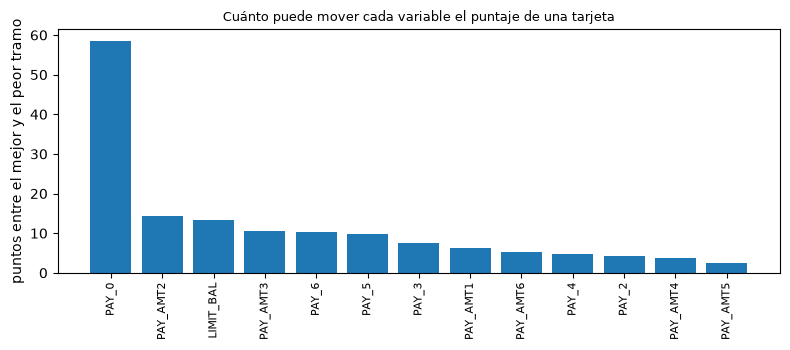

mayor y menor dispersión: PAY_0 58.5 PAY_AMT5 2.6


In [6]:
# La dispersión de puntos de cada variable, el mejor tramo menos el peor, desde la tabla versionada
spread = {}
for name in card["features"]:
    pts = [r["points_raw"] for r in table if r["feature"] == name and r["count"] > 0]
    spread[name] = max(pts) - min(pts)
order = sorted(spread, key=lambda n: -spread[n])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(order, [spread[n] for n in order], color="tab:blue")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.set_ylabel("puntos entre el mejor y el peor tramo")
ax.set_title("Cuánto puede mover cada variable el puntaje de una tarjeta", fontsize=9)
fig.tight_layout()
plt.show()
print("mayor y menor dispersión:", order[0], round(spread[order[0]], 1), order[-1], round(spread[order[-1]], 1))

`PAY_0` está solo: 58,5 puntos entre su mejor y su peor tramo, y luego una larga cola hasta `PAY_AMT5`, con 2,6. Las tres que le siguen (`PAY_AMT2`, `LIMIT_BAL` y `PAY_AMT3`) abarcan entre 10 y 14 puntos cada una, y las demás variables menos. La tarjeta de puntaje es entonces sobre todo un modelo del estado de pago con correcciones modestas. Esto dice también qué puede capturar una línea base de una sola variable y qué deben aportar las otras doce.

### Paso 5: la tarjeta de puntaje contra una línea base de una variable, en las 50 tarjetas

Un ajuste vale su complejidad solo si supera algo más simple. El ordenamiento más simple de la muestra es el valor crudo de `PAY_0` usado solo, que representa el peldaño P0 de la escalera. La función `disc_auc` del motor devuelve el AUC, la probabilidad de que un incumplidor quede sobre un buen pagador (Hanley y McNeil, 1982), y `disc_ks` la mayor distancia entre las distribuciones de puntaje de los incumplidores y del resto. `disc_delong` prueba la diferencia de dos AUC medidos sobre las mismas tarjetas, cuyas estimaciones están correlacionadas, con la covarianza de las dos curvas (DeLong, DeLong y Clarke-Pearson, 1988): su estadístico es la diferencia de AUC sobre su error estándar. La celda llama a las tres funciones sobre las 50 tarjetas.

In [7]:
# El motor sobre las 50 tarjetas: la tarjeta de puntaje contra el valor crudo de PAY_0 usado solo como orden
pd50 = np.array(sample["scorecard_pd"])
pay0_raw = np.array(inputs["PAY_0"], dtype=float)
auc_card = disc_auc(pd50, y50, policy=policy, model_id="P1-scorecard")
auc_one = disc_auc(pay0_raw, y50, policy=policy, model_id="P0-single")
ks_card = disc_ks(pd50, y50, policy=policy, model_id="P1-scorecard")
ks_one = disc_ks(pay0_raw, y50, policy=policy, model_id="P0-single")
duel = disc_delong(pd50, pay0_raw, y50, policy=policy, model_id="P1-scorecard")
print("AUC en 50 tarjetas (tarjeta de puntaje, solo PAY_0):", round(auc_card.metric, 4), round(auc_one.metric, 4))
print("KS en 50 tarjetas (tarjeta de puntaje, solo PAY_0):", round(ks_card.metric, 4), round(ks_one.metric, 4))
print("DeLong, tarjeta de puntaje contra solo PAY_0: z, p, luz:", round(duel.statistic, 2), round(duel.p_value, 4))
print(LIGHT[duel.light.value])

AUC en 50 tarjetas (tarjeta de puntaje, solo PAY_0): 0.7752 0.599
KS en 50 tarjetas (tarjeta de puntaje, solo PAY_0): 0.5048 0.2095
DeLong, tarjeta de puntaje contra solo PAY_0: z, p, luz: 2.55 0.0107
ámbar


En las 50 tarjetas la tarjeta de puntaje alcanza un AUC de 0,7752 y un KS de 0,5048, mientras `PAY_0` solo alcanza 0,599 y 0,2095. El estadístico de DeLong es 2,55 con un valor p de 0,0107, que la política por defecto pinta de ámbar. La tarjeta de puntaje supera a la línea base aquí, y el motor dice que es poco probable que sea azar, aun con solo 15 incumplidores. Cuán ancha es la incertidumbre de cada AUC es la siguiente pregunta: el AUC de un ordenamiento medido en 50 tarjetas es en sí una estimación.

### Paso 6: cuán seguro es un AUC de 50 tarjetas y cuán buena es la PD como pronóstico

`auc_with_variance` devuelve el AUC con su varianza y los conteos de incumplidores y buenos pagadores, de modo que un intervalo normal de 95% es el AUC más o menos $1{,}96\sqrt{\widehat{\mathrm{Var}}}$. La PD de una tarjeta de puntaje es también un pronóstico de un resultado 0/1, que `pd_brier` puntúa con el error cuadrático medio (menor es mejor) y `pd_ece` con el error de calibración esperado, la distancia media ponderada entre la PD media y la tasa observada por tramos. Una PD constante igual a la tasa de incumplimiento de la muestra es el pronóstico de referencia que todo modelo debe superar. La celda imprime los intervalos de ambos ordenamientos y los dos puntajes de pronóstico.

In [8]:
# El AUC de cada orden en las 50 tarjetas con su intervalo normal de 95%, y el Brier y el ECE de la PD
auc_a, var_a, _, _ = auc_with_variance(pd50, y50)
auc_b, var_b, _, _ = auc_with_variance(pay0_raw, y50)
for label, a, v in (("P1", auc_a, var_a), ("PAY_0", auc_b, var_b)):
    print("intervalo de 95% del AUC:", label, round(a - 1.96 * v ** 0.5, 3), round(a + 1.96 * v ** 0.5, 3))
brier_card = pd_brier(y50, pd50, policy=policy, model_id="P1-scorecard")
brier_flat = pd_brier(y50, np.full(len(y50), y50.mean()), policy=policy, model_id="P0-constant")
ece_card = pd_ece(y50, pd50, bins=5, policy=policy, model_id="P1-scorecard")
print("Brier en 50 tarjetas (tarjeta de puntaje, PD constante):", round(brier_card.metric, 4))
print(round(brier_flat.metric, 4))
print("ECE en 50 tarjetas (tarjeta de puntaje):", round(ece_card.metric, 4))

intervalo de 95% del AUC: P1 0.646 0.904
intervalo de 95% del AUC: PAY_0 0.419 0.779
Brier en 50 tarjetas (tarjeta de puntaje, PD constante): 0.1897
0.21
ECE en 50 tarjetas (tarjeta de puntaje): 0.1001


El intervalo del AUC de la tarjeta de puntaje va de 0,646 a 0,904 y el de `PAY_0` solo de 0,419 a 0,779, de modo que los dos se traslapan con 50 tarjetas; la comparación la lleva la prueba de DeLong pareada, no el traslape de los intervalos. El puntaje de Brier es 0,1897 para la tarjeta de puntaje frente a 0,21 de la PD constante, una ganancia modesta, y el ECE de 0,1001 en cinco tramos de diez tarjetas muestra lo poco que puede decir de la calibración una muestra de 50 tarjetas. Estos números motivan pasar a las 9.000 tarjetas reservadas.

### Paso 7: la misma comparación en 9.000 tarjetas reservadas

Las 9.000 tarjetas no están en el repositorio, pero el archivo de la muestra reservada versiona, para cada modelo, la curva CAP: la proporción acumulada de incumplidores detectados al cortar la población en pasos de 1% desde la tarjeta más riesgosa. La celda reconstruye desde esos escalones un vector de 9.000 valores de riesgo y resultados (100 rebanadas de 90 tarjetas, en orden decreciente de riesgo) y se lo entrega al motor para la línea base y para la tarjeta de puntaje. Dentro de una rebanada se pierde el orden de las tarjetas, así que las tarjetas de una rebanada cuentan como empates; el AUC versionado de las mismas tarjetas, calculado por la cadena de cálculo sobre las tarjetas mismas, se imprime junto al del motor, y se dibujan las curvas ROC de los dos modelos.

AUC y KS de las 9000 tarjetas reconstruidas: P0-single 0.6994 0.3573
AUC y KS de las 9000 tarjetas reconstruidas: P1-scorecard 0.7586 0.3956
AUC versionado (P0, P1): 0.6917 0.7587


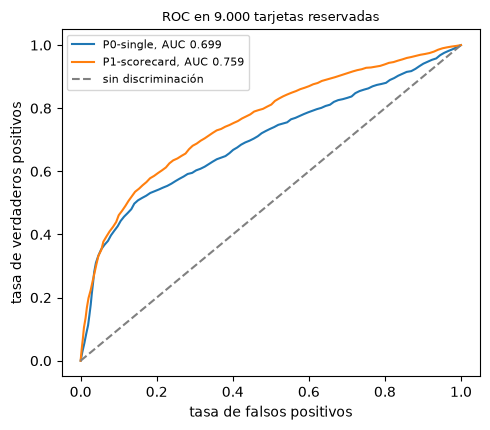

In [9]:
# Reconstruir 9000 tarjetas desde los escalones CAP de dos modelos (100 rebanadas de 90) y ejecutar el motor
n_cards, n_defaults = holdout["outputs"]["n"], holdout["outputs"]["defaults"]
rebuilt = {}
for rung in ("P0-single", "P1-scorecard"):
    per_slice = np.rint(np.diff(np.array(rungs[rung]["cap"]["defaults"])) * n_defaults).astype(int)
    size = n_cards // len(per_slice)
    risk = np.repeat(np.arange(len(per_slice), 0, -1), size)
    flags = np.concatenate([np.r_[np.ones(d), np.zeros(size - d)] for d in per_slice])
    auc = disc_auc(risk, flags, policy=policy, model_id=rung)
    ks = disc_ks(risk, flags, policy=policy, model_id=rung)
    rebuilt[rung] = (auc.metric, ks.metric)
    print("AUC y KS de las 9000 tarjetas reconstruidas:", rung, round(auc.metric, 4), round(ks.metric, 4))
tests = [t for t in holdout["tests"] if t["test_id"] == "disc.auc" and t["segment"] == "portfolio"]
committed = {t["model_id"]: t["metric"] for t in tests}
print("AUC versionado (P0, P1):", round(committed["P0-single"], 4), round(committed["P1-scorecard"], 4))
fig, ax = plt.subplots(figsize=(5, 4.4))
for rung in rebuilt:
    ax.plot(rungs[rung]["roc"]["fpr"], rungs[rung]["roc"]["tpr"], label=f"{rung}, AUC {rebuilt[rung][0]:.3f}")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="sin discriminación")
ax.set_xlabel("tasa de falsos positivos")
ax.set_ylabel("tasa de verdaderos positivos")
ax.set_title("ROC en 9.000 tarjetas reservadas", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

El motor devuelve un AUC de 0,7586 para la tarjeta de puntaje en las tarjetas reconstruidas frente al 0,7587 versionado: tratar como empates las 90 tarjetas de una rebanada cuesta una diezmilésima. Para la línea base de una variable el valor reconstruido, 0,6994, queda sobre el 0,6917 versionado. La razón es visible en la figura ROC: la línea base toma solo cuatro valores distintos de PD, así que su curva tiene tramos rectos largos donde miles de tarjetas están empatadas, y cortar un bloque de empates en rebanadas deja que el vector reconstruido ordene tarjetas que el modelo no puede ordenar. El AUC reconstruido es entonces confiable para un modelo con muchos puntajes distintos y optimista para uno con pocos. El KS dice lo mismo que el AUC: 0,3956 para la tarjeta de puntaje frente a 0,3573. La curva de la tarjeta de puntaje queda sobre la de la línea base en la mayor parte del rango, que es el significado visual de la ganancia de AUC.

### Paso 8: ordenar no es calibrar

Un mejor orden no garantiza mejores PD. Dos tablas versionadas responden la segunda pregunta para cada modelo: la tabla de grados, con las tarjetas, los incumplimientos y la PD media de cada grado de la escala maestra, y la tabla de confiabilidad, diez tramos de 900 tarjetas por PD. `pd_chi2_grades` prueba todos los grados a la vez contra sus PD medias (BCBS, 2005), y `pd_jeffreys` prueba el nivel del portafolio, de una cola, con las tarjetas, los incumplimientos y la PD media. La celda ejecuta ambas para los dos modelos y dibuja las curvas de confiabilidad: la PD media de cada tramo contra su tasa de incumplimiento observada, con la diagonal como calibración perfecta.

chi cuadrado sobre grados, p y luz: P0-single 0.5982 verde
prueba de nivel del portafolio, p de Jeffreys: P0-single 0.2645
chi cuadrado sobre grados, p y luz: P1-scorecard 0.0264 ámbar
prueba de nivel del portafolio, p de Jeffreys: P1-scorecard 0.3095


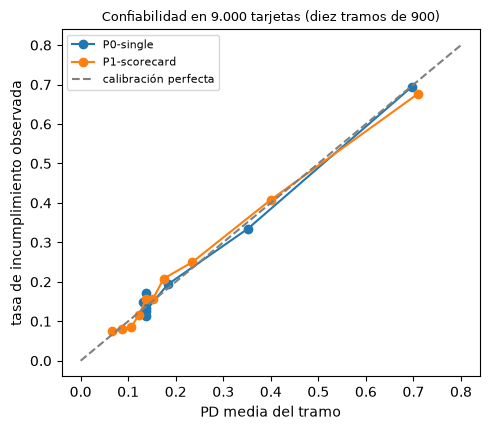

In [10]:
# Chi cuadrado sobre grados y prueba de nivel del portafolio, desde la tabla de grados versionada de cada modelo
fig, ax = plt.subplots(figsize=(5, 4.4))
for rung in ("P0-single", "P1-scorecard"):
    grades = [g for g in rungs[rung]["grades"] if g["n"] > 0]
    n_g, d_g, pd_g = [g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades]
    chi = pd_chi2_grades(n_g, d_g, pd_g, policy=policy, model_id=rung, segment="portfolio")
    mean_pd = sum(n * p for n, p in zip(n_g, pd_g)) / sum(n_g)
    level = pd_jeffreys(sum(n_g), sum(d_g), mean_pd, policy=policy, model_id=rung, segment="portfolio")
    print("chi cuadrado sobre grados, p y luz:", rung, round(chi.p_value, 4), LIGHT[chi.light.value])
    print("prueba de nivel del portafolio, p de Jeffreys:", rung, round(level.p_value, 4))
    bins_ = rungs[rung]["reliability"]
    ax.plot([b["pd"] for b in bins_], [b["dr"] for b in bins_], marker="o", label=rung)
ax.plot([0, 0.8], [0, 0.8], color="gray", linestyle="--", label="calibración perfecta")
ax.set_xlabel("PD media del tramo")
ax.set_ylabel("tasa de incumplimiento observada")
ax.set_title("Confiabilidad en 9.000 tarjetas (diez tramos de 900)", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

**Respuesta:** Sí, la tarjeta de puntaje ajustada gana sus variables, y la evidencia está en tarjetas que el ajuste nunca vio. El ajuste ve solo las 16.800 tarjetas de entrenamiento: las tres partes comparten una tasa de incumplimiento (la dispersión es 3e-05), las 13 variables retenidas mantienen cada tramo sobre 5% de las tarjetas (13 de 13) y siguen su dirección (13 de 13). El puntaje es una suma simple: 650 de 650 celdas de puntos y 50 de 50 puntajes se reconstruyen desde las entradas crudas y los puntos de corte. Frente a la línea base de una variable, el motor da sobre las 9.000 tarjetas reservadas reconstruidas un AUC de 0,7586 para la tarjeta de puntaje contra 0,6994 de `PAY_0` solo (versionados 0,7587 y 0,6917) y un KS de 0,3956 contra 0,3573. En la muestra de 50 tarjetas, la prueba de DeLong rechaza AUC iguales con un estadístico de 2,55 y un valor p de 0,0107.

La ganancia de orden no viene con mejor calibración. El chi cuadrado sobre grados es ámbar para la tarjeta de puntaje (p 0,0264) y verde para la línea base de una variable (p 0,5982), y la prueba de nivel es verde para ambos (p de Jeffreys 0,3095 y 0,2645). Un modelo con cuatro PD distintas es fácil de calibrar por grado y no puede ordenar bien. Las curvas de confiabilidad muestran a la tarjeta de puntaje siguiendo la diagonal en todo el rango, con pequeñas desviaciones en el centro, que el notebook 03 retoma.

Lo que este notebook no muestra: los errores estándar y los valores p del paso logístico, que el registro versionado no guarda (la revisión de signos del notebook 01 es su huella visible), un reajuste desde el archivo crudo (requiere la raíz de datos y las bibliotecas de la cadena de cálculo), ni ningún comportamiento fuera de tiempo: C01 es una sola fotografía de 2005, un límite que el notebook 07 enuncia como hallazgo.

## Resumen

- El ajuste es a prueba de fuga por diseño: una división estratificada con semilla fija, tramos y coeficientes aprendidos solo con las 16.800 tarjetas de entrenamiento, una parte de calibración separada para los retadores y una muestra reservada bloqueada.
- Los tramos aprendidos obedecen sus restricciones, lo que puede verificarse en los conteos versionados: al menos 5% de las tarjetas por tramo y una tasa de incumplimiento que sigue su dirección.
- Una tarjeta de puntaje es auditable: desde los valores crudos y los puntos de corte, la tabla de puntos reconstruye cada puntaje sin ningún objeto de modelo, y la dispersión de puntos por variable muestra lo que pondera.
- El AUC, el KS y las pruebas de DeLong del motor ubican a la tarjeta de puntaje sobre la línea base de una variable, mientras el chi cuadrado por grados muestra que un mejor orden no es una mejor calibración.

**Qué probar a continuación.** Reemplaza `PAY_0` por `PAY_2` como línea base de una variable en el paso 5 y mira cuánto cae el AUC; luego continúa con el notebook 03, que ejecuta la batería de validación sobre toda la escalera de modelos.

## Referencias

- Navas-Palencia, G. (2020), Optimal binning: mathematical programming formulation. https://arxiv.org/abs/2001.08025
- Siddiqi, N. (2017), Intelligent Credit Scoring, 2.ª ed., Wiley. https://doi.org/10.1002/9781119282396
- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- Este repositorio: `docs/guides/01_fetch-and-bake.md`, `docs/design/SDD.md` (la división a prueba de fuga de cada caso) y `data-pipeline/pipeline/model/scorecard.py` de la cadena de cálculo.